In [1]:
import os
os.makedirs('../src', exist_ok=True)

In [2]:
%%writefile ../src/preprocessing.py
import re, html, base64, unicodedata
import numpy as np
import pandas as pd
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer

try:
    _STOP = set(stopwords.words('english'))
except LookupError:
    nltk.download('stopwords')
    _STOP = set(stopwords.words('english'))
_STOP |= {'hou', 'ect', 'enron', 'nbsp'}
_STEMMER = PorterStemmer()

# ---------- decoding (base64 and quoted-printable emails) ----------
_SAFE_QP = re.compile(r'=([2-7][0-9A-F])')
_WS_QP = re.compile(r'=(0[9AD])')
_ALL_QP = re.compile(r'=([0-9A-F]{2})')
_LEAD_B64 = re.compile(r'^\s*[A-Za-z0-9+/\s]{80,}={0,2}')

def _try_b64(text):
    s = str(text)
    if ' ' in s.lstrip()[:60]:
        return s
    m = _LEAD_B64.match(s)
    if not m:
        return s
    raw = re.sub(r'[^A-Za-z0-9+/]', '', m.group(0))
    raw = raw[: len(raw) - (len(raw) % 4)]
    try:
        out = base64.b64decode(raw).decode('utf-8', errors='ignore')
    except Exception:
        return s
    printable = sum(c.isprintable() or c in '\r\n\t' for c in out) / max(len(out), 1)
    return (out + ' ' + s[m.end():]) if printable > 0.95 and len(out) > 20 else s

def decode_text(text):
    text = _try_b64(text)
    if len(_SAFE_QP.findall(text)) >= 3:
        text = re.sub(r'=\r?\n', '', text)
        text = _SAFE_QP.sub(lambda m: chr(int(m.group(1), 16)), text)
    text = _WS_QP.sub(' ', text)
    if len(_ALL_QP.findall(text)) >= 3:
        text = _ALL_QP.sub(lambda m: chr(int(m.group(1), 16)), text)
    text = unicodedata.normalize('NFKD', text)
    return ''.join(c for c in text if not unicodedata.combining(c))

# ---------- text cleaning for TF-IDF ----------
def preprocess_text(text):
    text = str(text).lower()
    text = html.unescape(text)
    text = re.sub(r'<.*?>', ' ', text)
    text = re.sub(r'http\S+|www\S+', ' ', text)
    text = re.sub(r'\S+@\S+', ' ', text)
    text = re.sub(r'[^a-z\s]', ' ', text)
    words = [w for w in text.split() if w not in _STOP and len(w) > 2]
    return ' '.join(_STEMMER.stem(w) for w in words)

# ---------- hand-made features ----------
def _rx(words):
    return re.compile(r'\b(?:' + '|'.join(re.escape(w) for w in words) + r')\b')

_URGENCY = _rx(['urgent', 'immediately', 'act now', 'hurry', 'asap', 'expire', 'expires',
                'expired', 'expiring', 'limited time', 'last chance', 'final notice',
                'final warning', 'deadline', 'today only'])
_AUTHORITY = _rx(['police', 'cbi', 'income tax', 'court', 'legal action', 'government',
                  'customs', 'bank official', 'rbi', 'arrest warrant', 'officer',
                  'department', 'federal', 'irs'])
_FINANCIAL = _rx(['transfer', 'wire', 'payment', 'pay now', 'bank account', 'account number',
                  'deposit', 'refund', 'fee', 'processing fee', 'claim your', 'send money',
                  'western union'])
_CREDENTIAL = _rx(['enter your otp', 'share your otp', 'verify your account',
                   'confirm your identity', 'enter your pin', 'enter your password',
                   'cvv', 'card number', 'security code', 'social security number', 'ssn'])
_URL = re.compile(r'http\S+|www\.\S+|\bbit\.ly/\S+|\bt\.me/\S+')
_PHONE = re.compile(r'\b\d{10,}\b|\+\d{1,3}[\s-]?\d{6,}')
_EMAIL = re.compile(r'\S+@\S+\.\S+')

def extract_features(text):
    t = str(text)
    low = t.lower()
    return {
        'message_length': len(t),
        'word_count': len(t.split()),
        'exclamation_count': t.count('!'),
        'caps_word_count': sum(1 for w in t.split() if w.isupper() and len(w) > 2),
        'has_urgency': int(bool(_URGENCY.search(low))),
        'has_authority_claim': int(bool(_AUTHORITY.search(low))),
        'has_financial_request': int(bool(_FINANCIAL.search(low))),
        'has_credential_request': int(bool(_CREDENTIAL.search(low))),
        'has_url': int(bool(_URL.search(t))),
        'has_phone_number': int(bool(_PHONE.search(t))),
        'has_email': int(bool(_EMAIL.search(t))),
    }

def features_df(series):
    return pd.DataFrame([extract_features(t) for t in series], index=series.index)

Writing ../src/preprocessing.py


In [3]:
import sys
sys.path.append('../src')
from preprocessing import decode_text, preprocess_text, extract_features

sample = "Dear customer, your SBI account will be blocked today. Update your KYC immediately using this link: http://bank-verify-now.in/verify"
print(preprocess_text(decode_text(sample)))
print(extract_features(sample))

encoded = "Mrs=2ELydia Johnson=2C I know this mail will come to you as a surprise=2C nevertheless=2E"
print(decode_text(encoded))

dear custom sbi account block today updat kyc immedi use link
{'message_length': 132, 'word_count': 17, 'exclamation_count': 0, 'caps_word_count': 2, 'has_urgency': 1, 'has_authority_claim': 0, 'has_financial_request': 0, 'has_credential_request': 0, 'has_url': 1, 'has_phone_number': 0, 'has_email': 0}
Mrs.Lydia Johnson, I know this mail will come to you as a surprise, nevertheless.


In [4]:
import sys
sys.path.append('../src')
import pandas as pd, numpy as np
from sklearn.model_selection import train_test_split
from preprocessing import decode_text, preprocess_text, features_df

cols = ['message', 'label', 'scam_type', 'source']
real = pd.read_csv('../data/processed/master_dataset_relabeled.csv')[cols]
syn_scam = pd.read_csv('../data/processed/synthetic_scam.csv')[cols]
syn_legit = pd.read_csv('../data/processed/synthetic_legit.csv')[cols]

data = pd.concat([real, syn_scam, syn_legit], ignore_index=True)
data['message'] = data['message'].fillna('').astype(str)
data['scam_type'] = data['scam_type'].fillna('none')
print(data.groupby(['source', 'label']).size())

# decode, then clean (this takes a few minutes)
data['text'] = data['message'].apply(decode_text)
data['processed_message'] = data['text'].apply(preprocess_text)

# 1) drop messages that became empty after cleaning
n0 = len(data)
data = data[data['processed_message'].str.strip() != ''].copy()
print("dropped empty:", n0 - len(data))

# 2) drop texts that appear with BOTH labels (ambiguous)
nl = data.groupby('processed_message')['label'].nunique()
conflict = set(nl[nl > 1].index)
data = data[~data['processed_message'].isin(conflict)].copy()
print("texts with conflicting labels dropped:", len(conflict))

# 3) drop duplicates
n1 = len(data)
data = data.drop_duplicates(subset='processed_message').reset_index(drop=True)
print("dropped duplicates:", n1 - len(data))
print(data.groupby(['source', 'label']).size())

# features
data = pd.concat([data, features_df(data['text'])], axis=1)

# one split for both models, stratified on label + source + scam_type
strat = data['label'] + '|' + data['source'] + '|' + data['scam_type']
_, test_idx = train_test_split(data.index, test_size=0.2, random_state=42, stratify=strat)
data['split'] = 'train'
data.loc[test_idx, 'split'] = 'test'

data.to_csv('../data/processed/final_dataset.csv', index=False)
print(data['split'].value_counts())
print(pd.crosstab(data['scam_type'], data['split']))

# sanity: the challenge set must not overlap the training data
ch = pd.read_csv('../data/processed/challenge_set.csv')
ch_proc = ch['message'].apply(lambda t: preprocess_text(decode_text(t)))
print("challenge texts also in the dataset:", ch_proc.isin(set(data['processed_message'])).sum())

source           label
fraud_email      legit     5913
                 scam      4329
job_posting      legit    15348
                 scam       718
phishing_email   legit    10979
                 scam      6558
sms              legit     4516
                 scam       653
synthetic        scam       169
synthetic_legit  legit      144
dtype: int64
dropped empty: 186
texts with conflicting labels dropped: 0
dropped duplicates: 1521
source           label
fraud_email      legit     5465
                 scam      4151
job_posting      legit    14968
                 scam       706
phishing_email   legit    10650
                 scam      6403
sms              legit     4434
                 scam       563
synthetic        scam       169
synthetic_legit  legit      111
dtype: int64
split
train    38096
test      9524
Name: count, dtype: int64
split           test  train
scam_type                  
advance_fee      689   2759
banking_kyc        8     32
digital_arrest    10     39
i

In [5]:
import sys; sys.path.append('../src')
import pandas as pd, numpy as np
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import precision_score, recall_score

data = pd.read_csv('../data/processed/final_dataset.csv')
data['processed_message'] = data['processed_message'].fillna('')
train = data[data['split'] == 'train'].reset_index(drop=True)
test = data[data['split'] == 'test'].reset_index(drop=True)

count_cols = ['message_length', 'word_count', 'exclamation_count', 'caps_word_count']
flag_cols = ['has_urgency', 'has_authority_claim', 'has_financial_request',
             'has_credential_request', 'has_url', 'has_phone_number', 'has_email']

def make_pipeline():
    pre = ColumnTransformer([
        ('tfidf', TfidfVectorizer(max_features=5000, ngram_range=(1, 2), min_df=5, max_df=0.8), 'processed_message'),
        ('counts', FunctionTransformer(np.log1p), count_cols),
        ('flags', 'passthrough', flag_cols),
    ])
    return Pipeline([('pre', pre),
                     ('clf', LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42))])

SYN_WEIGHT = 5
def weights(df):
    return np.where(df['source'].isin(['synthetic', 'synthetic_legit']), SYN_WEIGHT, 1.0)

y_train = (train['label'] == 'scam').astype(int)
y_test = (test['label'] == 'scam').astype(int)

# out-of-fold probabilities on the training data
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
strat = train['label'] + '|' + train['source']
oof = np.zeros(len(train))
for tr, va in skf.split(train, strat):
    m = make_pipeline()
    m.fit(train.iloc[tr], y_train.iloc[tr], clf__sample_weight=weights(train.iloc[tr]))
    oof[va] = m.predict_proba(train.iloc[va])[:, 1]

rows = []
for t in np.arange(0.20, 0.71, 0.05):
    p = (oof >= t).astype(int)
    rows.append((round(t, 2), recall_score(y_train, p), precision_score(y_train, p)))
cv_table = pd.DataFrame(rows, columns=['threshold', 'recall', 'precision'])
print(cv_table.round(3).to_string(index=False))

ok = cv_table[cv_table['precision'] >= 0.85]
FINAL_THRESHOLD = float(ok.sort_values('recall', ascending=False).iloc[0]['threshold'])
print("\nChosen threshold:", FINAL_THRESHOLD)

 threshold  recall  precision
      0.20   0.977      0.669
      0.25   0.968      0.734
      0.30   0.961      0.784
      0.35   0.952      0.824
      0.40   0.940      0.858
      0.45   0.928      0.880
      0.50   0.917      0.906
      0.55   0.906      0.923
      0.60   0.890      0.937
      0.65   0.873      0.949
      0.70   0.855      0.961

Chosen threshold: 0.4


In [6]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
import joblib, os
from preprocessing import decode_text, preprocess_text, features_df

FINAL_THRESHOLD = 0.40
model = make_pipeline()
model.fit(train, y_train, clf__sample_weight=weights(train))

os.makedirs('../models', exist_ok=True)
joblib.dump({'model': model, 'threshold': FINAL_THRESHOLD}, '../models/binary_pipeline.joblib')

# 1) regular test split
p_test = model.predict_proba(test)[:, 1]
pred = (p_test >= FINAL_THRESHOLD).astype(int)
print(classification_report(y_test, pred, target_names=['legit', 'scam']))
print("ROC-AUC:", round(roc_auc_score(y_test, p_test), 4))
print(confusion_matrix(y_test, pred))

# 2) per-source breakdown
rows = []
for s, g in test.groupby('source'):
    yt = (g['label'] == 'scam').astype(int).values
    yp = pred[g.index.values]
    rec = (yp[yt == 1] == 1).mean() if (yt == 1).any() else float('nan')
    fpr = (yp[yt == 0] == 1).mean() if (yt == 0).any() else float('nan')
    rows.append((s, len(g), int((yt == 1).sum()), round(rec, 3), int((yt == 0).sum()), round(fpr, 3)))
print(pd.DataFrame(rows, columns=['source', 'n', 'scams', 'recall', 'legit', 'false_alarm_rate']).to_string(index=False))

# 3) challenge set (48 scam + 12 legit, never trained on)
ch = pd.read_csv('../data/processed/challenge_set.csv')
ch['text'] = ch['message'].apply(decode_text)
ch['processed_message'] = ch['text'].apply(preprocess_text)
ch = pd.concat([ch, features_df(ch['text'])], axis=1)
ch['prob'] = model.predict_proba(ch)[:, 1]
ch['pred'] = (ch['prob'] >= FINAL_THRESHOLD).astype(int)

summary = ch.groupby('scam_type')['pred'].agg(['count', 'sum']).rename(columns={'sum': 'flagged_as_scam'})
print("\nChallenge set (for scam rows, flagged = caught; for 'none', flagged = false alarms):")
print(summary)

print("\nMissed scams:")
for _, r in ch[(ch['label'] == 'scam') & (ch['pred'] == 0)].iterrows():
    print(f"{r['prob']:.2f} | {r['scam_type']} | {r['message'][:110]}")
print("\nFalse alarms:")
for _, r in ch[(ch['label'] == 'legit') & (ch['pred'] == 1)].iterrows():
    print(f"{r['prob']:.2f} | {r['message'][:110]}")

              precision    recall  f1-score   support

       legit       0.98      0.95      0.97      7126
        scam       0.87      0.94      0.90      2398

    accuracy                           0.95      9524
   macro avg       0.92      0.95      0.93      9524
weighted avg       0.95      0.95      0.95      9524

ROC-AUC: 0.9879
[[6777  349]
 [ 136 2262]]
         source    n  scams  recall  legit  false_alarm_rate
    fraud_email 1922    829   0.989   1093             0.037
    job_posting 3135    141   0.567   2994             0.035
 phishing_email 3411   1281   0.956   2130             0.056
            sms 1000    113   0.912    887             0.094
      synthetic   34     34   1.000      0               NaN
synthetic_legit   22      0     NaN     22             0.091

Challenge set (for scam rows, flagged = caught; for 'none', flagged = false alarms):
                count  flagged_as_scam
scam_type                             
banking_kyc        12               11


In [7]:
mc_train = train[(train['label'] == 'scam') & (train['scam_type'] != 'unknown')]
mc_test = test[(test['label'] == 'scam') & (test['scam_type'] != 'unknown')]

model_mc = Pipeline([
    ('tfidf', TfidfVectorizer(max_features=3000, ngram_range=(1, 2), min_df=2, max_df=0.8)),
    ('clf', LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)),
])
model_mc.fit(mc_train['processed_message'], mc_train['scam_type'])
joblib.dump(model_mc, '../models/scamtype_pipeline.joblib')   # saved BEFORE the challenge set

print(mc_train['scam_type'].value_counts(), '\n')
pred_mc = model_mc.predict(mc_test['processed_message'])
print(classification_report(mc_test['scam_type'], pred_mc))

labels = sorted(mc_train['scam_type'].unique())
print(pd.DataFrame(confusion_matrix(mc_test['scam_type'], pred_mc, labels=labels),
                   index=labels, columns=labels))

# challenge set (the 48 scam messages only)
ch_s = ch[ch['label'] == 'scam'].copy()
ch_s['pred_type'] = model_mc.predict(ch_s['processed_message'])
print("\nChallenge accuracy by true type:")
print(ch_s.assign(ok=ch_s['pred_type'] == ch_s['scam_type']).groupby('scam_type')['ok'].agg(['sum', 'count']))
print(pd.crosstab(ch_s['scam_type'], ch_s['pred_type']))

print("\nWrong predictions:")
for _, r in ch_s[ch_s['pred_type'] != ch_s['scam_type']].iterrows():
    print(f"{r['scam_type']} -> {r['pred_type']} | {r['message'][:100]}")

scam_type
phishing          5122
advance_fee       2759
job_scam           570
lottery            118
digital_arrest      39
upi_payment         32
investment          32
banking_kyc         32
Name: count, dtype: int64 

                precision    recall  f1-score   support

   advance_fee       0.92      0.98      0.95       689
   banking_kyc       0.67      1.00      0.80         8
digital_arrest       1.00      0.90      0.95        10
    investment       1.00      0.88      0.93         8
      job_scam       0.95      0.98      0.96       142
       lottery       0.88      0.97      0.92        30
      phishing       0.99      0.94      0.96      1281
   upi_payment       0.62      1.00      0.76         8

      accuracy                           0.96      2176
     macro avg       0.88      0.95      0.90      2176
  weighted avg       0.96      0.96      0.96      2176

                advance_fee  banking_kyc  digital_arrest  investment  \
advance_fee             674    

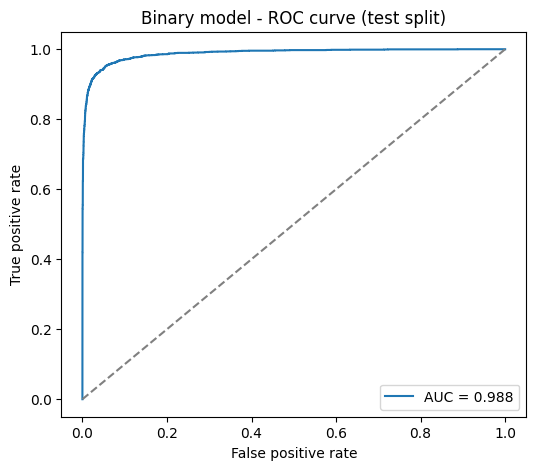

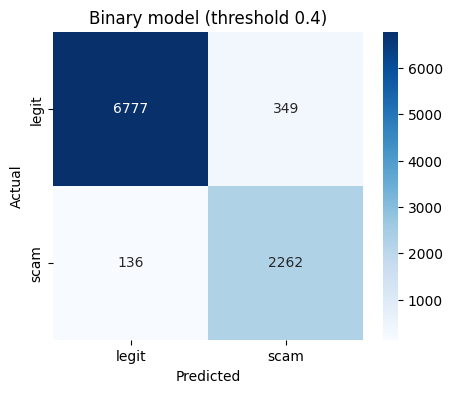

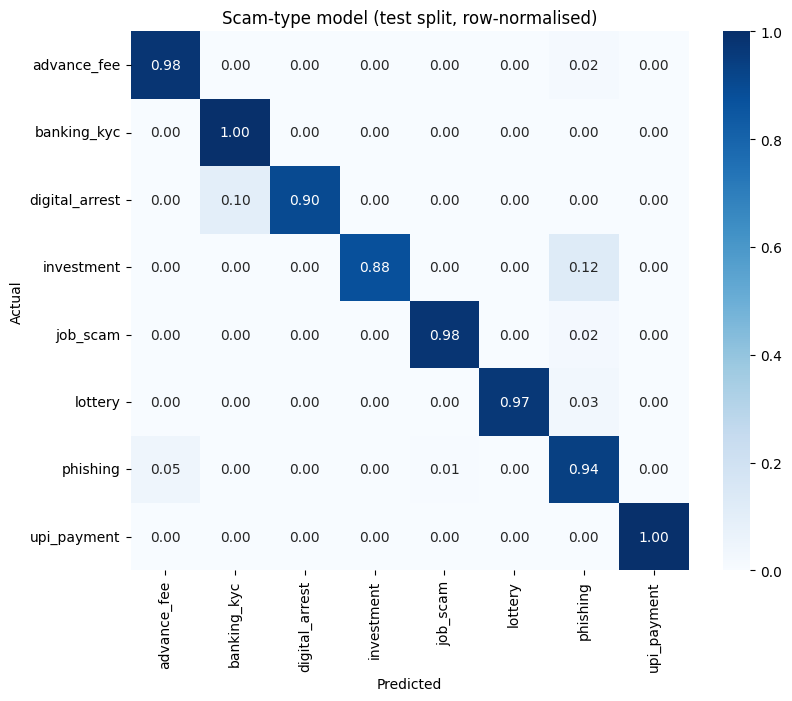

saved 60 rows


In [8]:
import matplotlib.pyplot as plt, seaborn as sns, os
from sklearn.metrics import roc_curve, f1_score

os.makedirs('../notebooks/figures', exist_ok=True)

# 1) ROC curve (binary, test split)
fpr, tpr, _ = roc_curve(y_test, p_test)
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f'AUC = {roc_auc_score(y_test, p_test):.3f}')
plt.plot([0, 1], [0, 1], '--', color='gray')
plt.xlabel('False positive rate'); plt.ylabel('True positive rate')
plt.title('Binary model - ROC curve (test split)'); plt.legend()
plt.savefig('../notebooks/figures/final_binary_roc.png', dpi=150, bbox_inches='tight'); plt.show()

# 2) Binary confusion matrix
cm = confusion_matrix(y_test, pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['legit', 'scam'], yticklabels=['legit', 'scam'])
plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.title(f'Binary model (threshold {FINAL_THRESHOLD})')
plt.savefig('../notebooks/figures/final_binary_confusion.png', dpi=150, bbox_inches='tight'); plt.show()

# 3) Scam-type confusion matrix, row-normalised (test split)
cm_mc = confusion_matrix(mc_test['scam_type'], pred_mc, labels=labels, normalize='true')
plt.figure(figsize=(9, 7))
sns.heatmap(cm_mc, annot=True, fmt='.2f', cmap='Blues', xticklabels=labels, yticklabels=labels)
plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.title('Scam-type model (test split, row-normalised)')
plt.savefig('../notebooks/figures/final_scamtype_confusion.png', dpi=150, bbox_inches='tight'); plt.show()

# 4) Save the challenge-set results as a table for the report
ch_out = ch[['message', 'label', 'scam_type', 'prob', 'pred']].copy()
ch_out.loc[ch_out['label'] == 'scam', 'pred_type'] = ch_s['pred_type'].reindex(ch_out.index)
ch_out.to_csv('../data/processed/challenge_results_v1.csv', index=False)
print("saved", len(ch_out), "rows")

# Stages 5-6: Modeling and Evaluation (Final v1)

## 1. Data
- **Real sources:** SMS spam, phishing emails, fraud ("419") emails, job postings. Cleaning: HTML stripped, quoted-printable and base64 emails decoded, empty and duplicate messages removed across all sources.
- **Synthetic scam messages (169):** digital_arrest 49, banking_kyc 40, upi_payment 40, investment 40. Written because the real corpora contain no genuine examples of these scams.
- **Synthetic legitimate messages (111 after de-duplication):** Indian bank alerts, OTP deliveries, genuine KYC reminders, Hinglish chat. They stop the model from learning "Indian banking language means scam".
- **Challenge set (60 messages):** 48 scams (12 per synthetic class) and 12 hard legit messages, written separately and never used for training or tuning.
- **Final dataset:** 47,620 rows. One stratified split (label + source + scam type) saved to disk: 38,096 train / 9,524 test.

## 2. Scam-type labels
- `phishing` and `job_scam` come from the source dataset. `advance_fee` and `lottery` come from whole-word keyword rules. Everything else is `unknown` and is excluded from the scam-type model (still scam for the binary model).
- The first-round keyword rules were replaced after an audit found they labeled advance-fee emails as banking_kyc, digital_arrest and investment.

## 3. Binary model (legit vs scam)
Logistic Regression (class-balanced), TF-IDF (1-2 grams) + 11 engineered features. Synthetic rows weighted 5x. **Threshold 0.40**, chosen by 5-fold cross-validation on training data only (highest recall with precision >= 0.85).

| Test split (n = 9,524) | Precision | Recall | F1 |
|---|---|---|---|
| scam | 0.87 | 0.94 | 0.90 |
| legit | 0.98 | 0.95 | 0.97 |

ROC-AUC 0.988. Confusion matrix: 6777 TN, 349 FP, 136 FN, 2262 TP.

| Source | Scam recall | False-alarm rate |
|---|---|---|
| fraud_email | 0.989 | 0.037 |
| phishing_email | 0.956 | 0.056 |
| sms | 0.912 | 0.094 |
| job_posting | **0.567** | 0.035 |

**Challenge set:** 41 of 48 scams caught (banking_kyc 11/12, digital_arrest 9/12, investment 11/12, upi_payment 10/12). 5 of 12 deliberately hard legitimate messages were flagged. Their text contained KYC/RBI/bank wording.

## 4. Scam-type model
Logistic Regression + TF-IDF on scam rows with a known type. Accuracy 0.96, macro F1 0.90 on the test split (n = 2,176).

| Class | Precision | Recall | Test rows | Training source |
|---|---|---|---|---|
| phishing | 0.99 | 0.94 | 1,281 | real |
| advance_fee | 0.92 | 0.98 | 689 | real |
| job_scam | 0.95 | 0.98 | 142 | real |
| lottery | 0.88 | 0.97 | 30 | real |
| digital_arrest | 1.00 | 0.90 | 10 | synthetic |
| banking_kyc | 0.67 | 1.00 | 8 | synthetic |
| investment | 1.00 | 0.88 | 8 | synthetic |
| upi_payment | 0.62 | 1.00 | 8 | synthetic |

**Challenge set (fresh synthetic messages): 30 of 48 correct** (banking_kyc 11/12, digital_arrest 7/12, investment 8/12, upi_payment 4/12). The four synthetic classes score much lower here than on the test split, so those scores partly measure writing style, not real-world scam patterns.

Typical confusions: bank-related messages go to banking_kyc, and "link + enter your PIN" messages go to phishing. These categories overlap in practice. The app will therefore show the top 3 likely types instead of one label.

## 5. Limitations
1. Four scam types (banking_kyc, digital_arrest, upi_payment, investment) have no real examples. They are trained on 32-39 synthetic messages each.
2. Fake job postings are caught at only ~57% in the test split.
3. Genuine messages that mention KYC, RBI or banks are sometimes flagged. The model reads topical words and cannot tell "RBI never asks for KYC" from a scam asking for it.
4. Some scam labels in the source datasets are noisy (fragments and ordinary text labeled scam).
5. Each real scam type comes mostly from one source dataset, so the model may partly learn the dataset's style.
6. The challenge set has only 60 messages. Class-to-class differences on it are not statistically reliable.

## 6. Design decisions
- Train/test split saved to disk, so every notebook uses the same test set.
- TF-IDF is fitted inside the pipeline, so it never sees test data.
- The threshold was chosen on training data only. The challenge set was evaluated once, after the models were saved, and nothing was tuned against it.

In [9]:
import joblib, sys
sys.path.append('../src')
import pandas as pd, numpy as np
from preprocessing import decode_text, preprocess_text, features_df

bundle = joblib.load('../models/binary_pipeline.joblib')
model, THRESH = bundle['model'], bundle['threshold']
pre, clf = model.named_steps['pre'], model.named_steps['clf']

count_cols = ['message_length', 'word_count', 'exclamation_count', 'caps_word_count']
flag_cols = ['has_urgency', 'has_authority_claim', 'has_financial_request',
             'has_credential_request', 'has_url', 'has_phone_number', 'has_email']
feat_names = list(pre.named_transformers_['tfidf'].get_feature_names_out()) + count_cols + flag_cols

def make_row(message):
    text = decode_text(message)
    row = pd.DataFrame({'processed_message': [preprocess_text(text)]})
    return pd.concat([row, features_df(pd.Series([text]))], axis=1)

def risk_level(p):
    if p >= 0.70: return 'Very high'
    if p >= 0.40: return 'High'
    if p >= 0.20: return 'Medium'
    return 'Low'

def explain_raw(message, top=6):
    row = make_row(message)
    prob = model.predict_proba(row)[0, 1]
    contrib = pre.transform(row).toarray()[0] * clf.coef_[0]
    order = np.argsort(contrib)
    print(f"Risk score {prob:.2f} -> {risk_level(prob)}")
    print("  pushes toward SCAM:", [(feat_names[i], round(float(contrib[i]), 2)) for i in order[::-1][:top] if contrib[i] > 0])
    print("  pushes toward LEGIT:", [(feat_names[i], round(float(contrib[i]), 2)) for i in order[:top] if contrib[i] < 0])

tests = [
    "This is Inspector Rao from Mumbai Cyber Crime. A parcel in your name contains illegal items. Stay on this video call and do not tell anyone or you will be arrested.",
    "SBI: Rs 450 debited from A/c ending 2231 on 05-Nov via UPI to Swiggy. Not you? Call 1800 112 211. Never share your OTP or PIN.",
    "Dear customer, your HDFC KYC is expired. Update immediately at http://hdfc-kyc-update.in/login or your account will be blocked today.",
    "Hey are we still meeting for lunch tomorrow? Let me know.",
]
for t in tests:
    print("\n", t[:80])
    explain_raw(t)


 This is Inspector Rao from Mumbai Cyber Crime. A parcel in your name contains il
Risk score 0.67 -> High
  pushes toward SCAM: [('message_length', 7.29), ('arrest', 0.96), ('illeg', 0.85), ('name', 0.45), ('video', 0.26), ('contain', 0.15)]
  pushes toward LEGIT: [('word_count', -3.71), ('anyon', -0.44), ('tell', -0.36), ('item', -0.27), ('call', -0.14)]

 SBI: Rs 450 debited from A/c ending 2231 on 05-Nov via UPI to Swiggy. Not you? C
Risk score 0.04 -> Low
  pushes toward SCAM: [('message_length', 6.92), ('never', 0.46)]
  pushes toward LEGIT: [('word_count', -3.53), ('end', -0.73), ('nov', -0.59), ('share', -0.53), ('caps_word_count', -0.24), ('has_credential_request', -0.21)]

 Dear customer, your HDFC KYC is expired. Update immediately at http://hdfc-kyc-u
Risk score 0.88 -> Very high
  pushes toward SCAM: [('message_length', 6.99), ('expir', 1.21), ('immedi', 1.06), ('account', 0.75), ('block', 0.57), ('dear', 0.12)]
  pushes toward LEGIT: [('word_count', -3.15), ('updat', -0.6

### Rule Layer for warning ###

In [1]:
%%writefile ../src/explain.py
import re

I = re.I

SIGNALS = [
    dict(key='urgency', title='Pressure to act fast',
         why='Scammers rush you so you do not stop to think or check.',
         patterns=[re.compile(r"\b(urgent(ly)?|immediately|asap|hurry|final (notice|warning|reminder)|last chance|expir(es|ed|ing|y)|within \d+ ?(min(ute)?s?|hours?|hrs?)|before midnight|tonight|right now)\b", I)]),
    dict(key='threat', title='Threat of arrest, blocking or legal action',
         why='Threats are used to scare people into acting without thinking.',
         patterns=[re.compile(r"\b(arrest(ed)?|warrant|legal action|jail|fir|case (is )?(registered|filed)|blocked?|suspended?|frozen|freeze[sd]?|deactivated?|disconnected?|closure|seized|detained|detention|prosecut\w+)\b", I)]),
    dict(key='authority', title='Mentions or claims to be a government body, police or court',
         why='Scammers often pretend to be police, CBI, customs, TRAI, RBI or a court.',
         patterns=[re.compile(r"\b(cbi|enforcement directorate|narcotics|ncb|customs|trai|rbi|police|cyber ?(crime|cell|branch)|income tax|supreme court|high court|interpol|nia|(sub-?)?inspector)\b", I)]),
    dict(key='secrecy', title='Asks you to keep it secret or stay on the line',
         why='Real agencies and banks do not tell you to hide a matter from your family or keep a call open.',
         patterns=[re.compile(r"\b(do not|don't|dont|never|mat)\s+(tell|inform|share|discuss|contact)\b[^.]{0,25}\b(anyone|any one|anybody|nobody|family|parents|relatives|lawyer)\b", I),
                   re.compile(r"\bkeep (this|it|the matter)[^.]{0,15}(confidential|secret)\b|\bstrictly confidential\b|\bkeep this matter confidential\b", I),
                   re.compile(r"\b(do not|don't|dont|never)\s+(disconnect|hang up|cut)\b|\bstay on (the |this )?(call|video)\b|\bkeep (your )?(camera|video) on\b|\bphone mat kaat", I),
                   re.compile(r"\bkisi ko[^.]{0,20}(na|mat)\s+bata", I)]),
    dict(key='credential', title='Asks for an OTP, PIN, password or card details',
         why='A genuine bank or agency never asks you to share these.', negatable=True,
         patterns=[re.compile(r"\b(share|send|enter|tell|reply with|provide|submit|give|read out|dalein|bhejo|bhejein|batayein|bataiye)\b[^.]{0,40}\b(otp|upi pin|pin|cvv|password|card number|aadhaar|aadhar|pan)\b", I),
                   re.compile(r"\benter your (upi )?pin\b", I)]),
    dict(key='payment', title='Asks you to pay or transfer money',
         why='Being asked to pay a fee or move money to a "safe" or "verification" account is a classic scam step.',
         patterns=[re.compile(r"\b(pay|transfer|send|deposit)\b[^.]{0,40}\b(rs\.?|inr|usd|fee|amount|balance|money|funds|deposit)\b", I),
                   re.compile(r"\b(verification|processing|clearance|registration|joining) (fee|charge|amount)\b|\bsafe account\b|\bverification account\b", I)]),
    dict(key='prize', title='Prize, cashback or reward hook',
         why='You cannot win a prize you never entered. Rewards are used as bait.',
         patterns=[re.compile(r"\b(you (have )?(just )?won|winner|prize|lottery|jackpot|cashback|congratulations|scratch card|claim (your|ur|yr))\b", I)]),
    dict(key='returns', title='Promises of guaranteed or unusually high returns',
         why='No genuine investment guarantees profit or doubles your money quickly.',
         patterns=[re.compile(r"\b(guaranteed (returns?|profit)|double your (money|investment)|risk[- ]free|sure[- ]shot|no risk|100% safe|crypto(currency)?|forex|trading (group|bot|signals)|\d+ ?% (daily|weekly|monthly|returns?|profit))\b", I)]),
    dict(key='upi_trick', title='Asks you to approve a request or scan a code to receive money',
         why='You never need your PIN, a QR scan or a collect-request approval to receive money.',
         patterns=[re.compile(r"\b(collect request|scan (this|the)? ?qr|qr code|approve (the|this|pending)?[^.]{0,15}request)\b", I)]),
]

_URL = re.compile(r"(?:https?://|www\.)\S+|\b(?:bit\.ly|tinyurl\.com|t\.me|wa\.me|goo\.gl|rb\.gy|cutt\.ly)/\S+", I)
_BAIT = re.compile(r"kyc|verify|secure|update|login|refund|claim|pay|reward|reverify|portal", I)
_NEGATIONS = ['do not', "don't", 'dont', 'never', 'not ', 'no one', 'nobody', 'kabhi nahi', ' mat ']

def _negated(text, start):
    before = text[max(0, start - 25):start].lower()
    return any(n in before for n in _NEGATIONS)

def _suspicious_link(text):
    for u in _URL.findall(text):
        host = re.sub(r"^(https?://)?(www\.)?", "", u, flags=I).split('/')[0].lower()
        shortener = host in ('bit.ly', 'tinyurl.com', 't.me', 'wa.me', 'goo.gl', 'rb.gy', 'cutt.ly')
        is_ip = bool(re.fullmatch(r"\d{1,3}(\.\d{1,3}){3}(:\d+)?", host))
        spoof = '-' in host and bool(_BAIT.search(host))
        if shortener or is_ip or spoof:
            return u
    return None

def detect(text):
    text = str(text)
    found = []
    for s in SIGNALS:
        ev = None
        for p in s['patterns']:
            for m in p.finditer(text):
                if s.get('negatable') and _negated(text, m.start()):
                    continue
                ev = text[max(0, m.start() - 15): m.end() + 25].replace('\n', ' ').strip()
                break
            if ev:
                break
        if ev:
            found.append(dict(key=s['key'], title=s['title'], why=s['why'], evidence=ev))
    link = _suspicious_link(text)
    if link:
        found.append(dict(key='link', title='Suspicious link',
                          why='The link is shortened, an IP address, or a look-alike address that mixes bank-style words. Real banks use their own plain domains.',
                          evidence=link))
    return found

GENERAL = [
    "Never share your OTP, PIN, CVV or password with anyone, even someone claiming to be from a bank or police.",
    "Do not send money because of pressure or threats. Take time and talk to someone you trust first.",
    "Verify independently: use the phone number on your card, the official app or website (typed yourself), or visit the branch.",
    "If money is already lost, call 1930 or report at cybercrime.gov.in as soon as possible.",
]
BY_TYPE = {
    'digital_arrest': "Police, CBI, customs or courts do not arrest people over a video call or ask for money to a 'safe account'. Hang up, do not pay, and tell a family member.",
    'banking_kyc': "Banks do not ask you to complete KYC through a link, WhatsApp or by sharing an OTP. Update KYC only at the branch or in the official app.",
    'upi_payment': "You never need your UPI PIN, a QR scan or a collect-request approval to receive money. Do not approve requests you did not start.",
    'investment': "No investment can guarantee returns. Check that the adviser is registered on the SEBI website and do not join tip groups on Telegram or WhatsApp.",
    'phishing': "Do not click the link. Open the official website by typing its address yourself.",
    'advance_fee': "Strangers who offer you a share of a large sum are scammers. Never pay a fee to receive money.",
    'job_scam': "Genuine employers do not ask you to pay for a job, a kit or training. Check the company on its official website.",
    'lottery': "You cannot win a lottery you did not enter. Never pay a fee or share details to claim a prize.",
}
BY_SIGNAL = {
    'secrecy': "Being told to keep something secret is a red flag. Tell a family member or friend about this message right now.",
    'link': "Do not click the link. Type the official address yourself if you need to check something.",
    'urgency': "Pressure to act within minutes is a tactic. A real bank or agency will allow you time to verify.",
}

def advice_for(scam_types=(), signal_keys=(), max_items=6):
    out = []
    for t in scam_types:
        if t in BY_TYPE:
            out.append(BY_TYPE[t])
    for k in signal_keys:
        if k in BY_SIGNAL:
            out.append(BY_SIGNAL[k])
    out += GENERAL
    seen, final = set(), []
    for a in out:
        if a not in seen:
            seen.add(a)
            final.append(a)
    return final[:max_items]

Writing ../src/explain.py


#### Test ithout ML model ####

In [2]:
import sys, importlib
sys.path.append('../src')
import explain
importlib.reload(explain)

tests = [
    "This is Inspector Rao from Mumbai Cyber Crime. A parcel in your name contains illegal items. Stay on this video call and do not tell anyone or you will be arrested.",
    "SBI: Rs 450 debited from A/c ending 2231 on 05-Nov via UPI to Swiggy. Not you? Call 1800 112 211. Never share your OTP or PIN.",
    "Dear customer, your HDFC KYC is expired. Update immediately at http://hdfc-kyc-update.in/login or your account will be blocked today.",
    "Hey are we still meeting for lunch tomorrow? Let me know.",
    "RBI has clarified that it never contacts citizens over phone or WhatsApp for KYC or account blocking. Do not click on unknown links.",
    "Google Pay: Your UPI ID is being deactivated. Reply YES and enter your UPI PIN on the link to keep it active: gpay-upi-active.in",
]
for t in tests:
    print("\n", t[:70])
    for s in explain.detect(t):
        print(f"  - {s['title']}  |  \"{s['evidence']}\"")


 This is Inspector Rao from Mumbai Cyber Crime. A parcel in your name c
  - Threat of arrest, blocking or legal action  |  "or you will be arrested."
  - Mentions or claims to be a government body, police or court  |  "This is Inspector Rao from Mumbai Cyber Cr"
  - Asks you to keep it secret or stay on the line  |  "video call and do not tell anyone or you will be arrested."

 SBI: Rs 450 debited from A/c ending 2231 on 05-Nov via UPI to Swiggy. 

 Dear customer, your HDFC KYC is expired. Update immediately at http://
  - Pressure to act fast  |  "ur HDFC KYC is expired. Update immediately at h"
  - Threat of arrest, blocking or legal action  |  "ccount will be blocked today."
  - Suspicious link  |  "http://hdfc-kyc-update.in/login"

 Hey are we still meeting for lunch tomorrow? Let me know.

 RBI has clarified that it never contacts citizens over phone or WhatsA
  - Mentions or claims to be a government body, police or court  |  "RBI has clarified that it ne"

 Google Pay: Your UPI

#### Combine everything into one function ####

In [1]:
%%writefile ../src/scamshield.py
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
from preprocessing import decode_text, preprocess_text, features_df
import explain

_MODELS = Path(__file__).resolve().parent.parent / 'models'
_bundle = joblib.load(_MODELS / 'binary_pipeline.joblib')
_model, THRESHOLD = _bundle['model'], _bundle['threshold']
_model_mc = joblib.load(_MODELS / 'scamtype_pipeline.joblib')

LEVELS = ['Low', 'Medium', 'High', 'Very high']

def _level(p):
    if p >= 0.70: return 'Very high'
    if p >= 0.40: return 'High'
    if p >= 0.20: return 'Medium'
    return 'Low'

def analyze(message):
    message = str(message or '')
    text = decode_text(message)
    processed = preprocess_text(text)

    if len(processed.split()) < 2:
        return dict(score=None, level='Low', bumped_by_rules=False, types=[],
                    signals=[], advice=explain.GENERAL[:2],
                    note='This message is too short to assess.')

    row = pd.concat([pd.DataFrame({'processed_message': [processed]}),
                     features_df(pd.Series([text]))], axis=1)
    prob = float(_model.predict_proba(row)[0, 1])
    level = _level(prob)

    signals = explain.detect(text)
    keys = [s['key'] for s in signals]

    bumped = False
    if level == 'Low' and (set(keys) & {'credential', 'secrecy', 'upi_trick'} or len(keys) >= 3):
        level, bumped = 'Medium', True

    types = []
    if prob >= 0.20 or bumped:
        probs = _model_mc.predict_proba([processed])[0]
        order = np.argsort(probs)[::-1][:3]
        types = [(str(_model_mc.classes_[i]), float(probs[i])) for i in order]

    top_types = [t for t, p in types if p >= 0.20][:2]
    return dict(score=prob, level=level, bumped_by_rules=bumped, types=types,
                signals=signals, advice=explain.advice_for(top_types, keys), note='')

Writing ../src/scamshield.py


In [2]:
import sys, importlib
sys.path.append('../src')
import explain; importlib.reload(explain)
import scamshield; importlib.reload(scamshield)
from scamshield import analyze

tests = [
    "This is Inspector Rao from Mumbai Cyber Crime. A parcel in your name contains illegal items. Stay on this video call and do not tell anyone or you will be arrested.",
    "SBI: Rs 450 debited from A/c ending 2231 on 05-Nov via UPI to Swiggy. Not you? Call 1800 112 211. Never share your OTP or PIN.",
    "Dear customer, your HDFC KYC is expired. Update immediately at http://hdfc-kyc-update.in/login or your account will be blocked today.",
    "Hey are we still meeting for lunch tomorrow? Let me know.",
    "Google Pay: Your UPI ID is being deactivated. Reply YES and enter your UPI PIN on the link to keep it active: gpay-upi-active.in",
    "ok",
]
for t in tests:
    r = analyze(t)
    score = 'n/a' if r['score'] is None else f"{r['score']:.2f}"
    print("\n", t[:70])
    print(f"  RISK: {r['level']} (score {score}){'  [raised by rule check]' if r['bumped_by_rules'] else ''}")
    if r['note']: print("  note:", r['note'])
    if r['types']: print("  looks like:", [(t_, round(p, 2)) for t_, p in r['types']])
    for s in r['signals']: print("  sign:", s['title'])
    print("  advice:", r['advice'][:2])


 This is Inspector Rao from Mumbai Cyber Crime. A parcel in your name c
  RISK: High (score 0.67)
  looks like: [('digital_arrest', 0.99), ('phishing', 0.0), ('lottery', 0.0)]
  sign: Threat of arrest, blocking or legal action
  sign: Mentions or claims to be a government body, police or court
  sign: Asks you to keep it secret or stay on the line
  advice: ["Police, CBI, customs or courts do not arrest people over a video call or ask for money to a 'safe account'. Hang up, do not pay, and tell a family member.", 'Being told to keep something secret is a red flag. Tell a family member or friend about this message right now.']

 SBI: Rs 450 debited from A/c ending 2231 on 05-Nov via UPI to Swiggy. 
  RISK: Low (score 0.04)
  advice: ['Never share your OTP, PIN, CVV or password with anyone, even someone claiming to be from a bank or police.', 'Do not send money because of pressure or threats. Take time and talk to someone you trust first.']

 Dear customer, your HDFC KYC is expired. Upd

## Streamlit app ##

In [3]:
%pip install streamlit 
import sys
print(sys.executable)


  Attempting uninstall: protobuf

    Found existing installation: protobuf 7.34.1

    Uninstalling protobuf-7.34.1:

      Successfully uninstalled protobuf-7.34.1

   ---------------------------------------- 0/2 [protobuf]
   ---------------------------------------- 0/2 [protobuf]
   ---------------------------------------- 0/2 [protobuf]
  Attempting uninstall: packaging
   ---------------------------------------- 0/2 [protobuf]
    Found existing installation: packaging 25.0
   ---------------------------------------- 0/2 [protobuf]
    Uninstalling packaging-25.0:
   ---------------------------------------- 0/2 [protobuf]
      Successfully uninstalled packaging-25.0
   ---------------------------------------- 0/2 [protobuf]
   -------------------- ------------------- 1/2 [packaging]
   ---------------------------------------- 2/2 [packaging]

Note: you may need to restart the kernel to use updated packages.
c:\Users\shiv_\anaconda3\python.exe


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
replit 4.1.2 requires protobuf<5.0.0,>=4.21.8, but you have protobuf 6.33.6 which is incompatible.
spyder 6.0.7 requires ipython!=8.17.1,<9.0.0,>=8.13.0; python_version > "3.8", but you have ipython 9.4.0 which is incompatible.
spyder-kernels 3.0.5 requires ipython!=8.17.1,<9,>=8.13.0; python_version > "3.8", but you have ipython 9.4.0 which is incompatible.

[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
print(sys.executable)

c:\Users\shiv_\anaconda3\python.exe


In [5]:
import os
os.makedirs('../app', exist_ok=True)

In [6]:
%%writefile ../app/app.py
import sys
from pathlib import Path
sys.path.insert(0, str(Path(__file__).resolve().parent.parent / 'src'))

import streamlit as st
from scamshield import analyze, THRESHOLD

st.set_page_config(page_title="AI ScamShield", page_icon="🛡️", layout="centered")

COLORS = {'Low': '#2e7d32', 'Medium': '#f9a825', 'High': '#ef6c00', 'Very high': '#c62828'}
TYPE_NAMES = {
    'digital_arrest': 'Digital arrest / authority impersonation',
    'banking_kyc': 'Banking / KYC fraud',
    'upi_payment': 'UPI / payment scam',
    'investment': 'Investment scam',
    'phishing': 'Phishing',
    'advance_fee': 'Advance-fee ("419") scam',
    'job_scam': 'Job scam',
    'lottery': 'Lottery / prize scam',
}
SAMPLES = {
    "Fake inspector": "This is Inspector Rao from Mumbai Cyber Crime. A parcel in your name contains illegal items. Stay on this video call and do not tell anyone or you will be arrested.",
    "Fake KYC": "Dear customer, your HDFC KYC is expired. Update immediately at http://hdfc-kyc-update.in/login or your account will be blocked today.",
    "Tip group": "Join our VIP Telegram group: guaranteed 30% monthly returns, zero risk. Limited seats, deposit Rs 5000 today. t.me/vip_profit_club",
    "Bank alert": "SBI: Rs 450 debited from A/c ending 2231 on 05-Nov via UPI to Swiggy. Not you? Call 1800 112 211. Never share your OTP or PIN.",
    "Casual chat": "Hey are we still meeting for lunch tomorrow? Let me know.",
}

st.session_state.setdefault('msg', '')

st.title("🛡️ AI ScamShield")
st.caption("An early-warning tool. It estimates how suspicious a message looks. It cannot prove that a message is a scam or that it is safe.")

st.write("Try an example:")
cols = st.columns(len(SAMPLES))
for col, (label, text) in zip(cols, SAMPLES.items()):
    if col.button(label, use_container_width=True):
        st.session_state.msg = text

message = st.text_area("Paste a suspicious SMS, WhatsApp message, email or link:", key='msg', height=160)
check = st.button("Check message", type="primary")

if check:
    if not message.strip():
        st.warning("Please paste a message first.")
    else:
        r = analyze(message)
        color = COLORS[r['level']]
        st.markdown(
            f"<div style='padding:16px;border-radius:10px;background:{color};color:white;'>"
            f"<span style='font-size:14px'>Risk level</span><br>"
            f"<span style='font-size:32px;font-weight:700'>{r['level']}</span></div>",
            unsafe_allow_html=True)

        if r['score'] is not None:
            st.progress(min(max(r['score'], 0.0), 1.0))
            st.caption(f"Model score: {r['score']:.2f} (0 = looks normal, 1 = looks very much like known scams). "
                       f"Messages scoring {THRESHOLD:.2f} or more are flagged as likely scams.")
        if r['bumped_by_rules']:
            st.info("The model score was low, but the message contains strong warning signs, so the level was raised to Medium.")
        if r['note']:
            st.info(r['note'])

        shown = [(t, p) for t, p in r['types'] if p >= 0.20]
        if shown:
            st.subheader("What type of scam does it resemble?")
            for t, p in shown:
                st.write(f"**{TYPE_NAMES.get(t, t)}** ({p:.0%})")
                st.progress(min(max(p, 0.0), 1.0))
            st.caption("Scam types overlap in real life, so up to three are shown. This is a guess from the message wording.")

        if r['signals']:
            st.subheader("Warning signs found")
            for s in r['signals']:
                with st.expander(s['title'], expanded=True):
                    st.write(s['why'])
                    st.code(s['evidence'], language=None)
            st.caption("Warning signs are rule-based checks shown next to the score. They are not a breakdown of how the model calculated it.")
        elif r['score'] is not None:
            st.success("No common scam warning signs were found.")

        st.subheader("What to do next")
        for a in r['advice']:
            st.markdown(f"- {a}")
        if r['level'] == 'Low':
            st.caption("Low risk does not mean safe. If a message asks for money, OTPs or personal details, verify it independently.")

with st.sidebar:
    st.header("About")
    st.write("AI ScamShield scores messages with a machine-learning model, then adds rule-based checks for common scam tactics.")
    st.header("Limitations")
    st.write(
        "- It can be wrong in both directions: scams may look safe, and genuine messages (for example a real bank notice that mentions KYC) may look risky.\n"
        "- Scam-type labels for UPI, digital arrest, banking KYC and investment scams were learned mostly from messages we wrote ourselves.\n"
        "- It does not check links or phone numbers against any live database.\n"
        "- It is not a substitute for your bank, the police or your own judgement."
    )
    st.write("If you have lost money to fraud, call **1930** or report at cybercrime.gov.in.")

Writing ../app/app.py
